In [1]:
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/houdaelidrissiencg/CC-PARTIE-A/blob/main/CC-Partie%20A.ipynb)

SyntaxError: unmatched ']' (1596329470.py, line 1)

Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)
Q1 — Présentation (8 à 12 lignes). Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la définition de tous ses symboles. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

Q2 — Schéma original. Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

Q3 — Contextes d'utilisation. Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

Q4 — Analyse expérimentale. Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier au moins un hyperparamètre pour discuter son effet. Ne pas inventer de résultats.

À ajouter par les étudiants sous chaque algorithme : « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

Q1 — Présentation (8 à 12 lignes). Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la définition de tous ses symboles. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

In [14]:
# A.0 — installation
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [15]:
# A.0bis — imports communs et graine globale
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn, warnings
warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)
print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.6.1 | numpy 2.4.6 | pandas 2.2.3


In [20]:
# Préparation des jeux réels scikit-learn (utilisés en Q4)
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, accuracy_score, silhouette_score)

jeu_reg = load_diabetes(); X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer(); X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_wine = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(
        StandardScaler().fit_transform(jeu_wine.data))
jeu_img = load_digits(); X_img = StandardScaler().fit_transform(jeu_img.data)

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_cls, y_cls, test_size=.25,
                                              stratify=y_cls, random_state=GRAINE)
print("Diabetes", X_reg.shape, "| Cancer", X_cls.shape, "| Wine", X_clu.shape, "| Digits", X_img.shape)

Diabetes (442, 10) | Cancer (569, 30) | Wine (178, 2) | Digits (1797, 64)


In [21]:
from sklearn.linear_model import LinearRegression
m = LinearRegression().fit(Xr_tr, yr_tr); p = m.predict(Xr_te)
print("RMSE:", mean_squared_error(yr_te, p)**.5, "R²:", r2_score(yr_te, p))
# Q4 — variation : ajout de Ridge pour comparer
from sklearn.linear_model import Ridge
for a in [0.1, 1, 10, 100]:
    mm = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_tr, yr_tr)
    print(f"Ridge alpha={a:>4} MAE={mean_absolute_error(yr_te, mm.predict(Xr_te)):.3f}")

RMSE: 53.369566710321955 R²: 0.4849058889476756
Ridge alpha= 0.1 MAE=41.543
Ridge alpha=   1 MAE=41.507
Ridge alpha=  10 MAE=41.459
Ridge alpha= 100 MAE=41.927


In [22]:
from sklearn.linear_model import Ridge
for a in [0.1, 1, 10, 25, 100, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_tr, yr_tr)
    print(f"alpha={a:>5} MAE={mean_absolute_error(yr_te, m.predict(Xr_te)):.3f}")

alpha=  0.1 MAE=41.543
alpha=    1 MAE=41.507
alpha=   10 MAE=41.459
alpha=   25 MAE=41.491
alpha=  100 MAE=41.927
alpha= 1000 MAE=50.437


In [23]:
from sklearn.linear_model import Lasso
for a in [0.01, 0.1, 0.5, 1, 3, 10]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=15000)).fit(Xr_tr, yr_tr)
    print(f"alpha={a:>5} R²={r2_score(yr_te, m.predict(Xr_te)):.3f} "
          f"coefs_non_nuls={(m[-1].coef_!=0).sum()}")

alpha= 0.01 R²=0.485 coefs_non_nuls=10
alpha=  0.1 R²=0.487 coefs_non_nuls=9
alpha=  0.5 R²=0.491 coefs_non_nuls=9
alpha=    1 R²=0.496 coefs_non_nuls=9
alpha=    3 R²=0.501 coefs_non_nuls=6
alpha=   10 R²=0.478 coefs_non_nuls=4


In [19]:
from sklearn.linear_model import LinearRegression
m = LinearRegression().fit(Xr_tr, yr_tr); p = m.predict(Xr_te)
print("RMSE:", mean_squared_error(yr_te, p)**.5, "R²:", r2_score(yr_te, p))
# Q4 — variation : ajout de Ridge pour comparer
from sklearn.linear_model import Ridge
for a in [0.1, 1, 10, 100]:
    mm = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_tr, yr_tr)
    print(f"Ridge alpha={a:>4} MAE={mean_absolute_error(yr_te, mm.predict(Xr_te)):.3f}")

RMSE: 53.369566710321955 R²: 0.4849058889476756
Ridge alpha= 0.1 MAE=41.543
Ridge alpha=   1 MAE=41.507
Ridge alpha=  10 MAE=41.459
Ridge alpha= 100 MAE=41.927


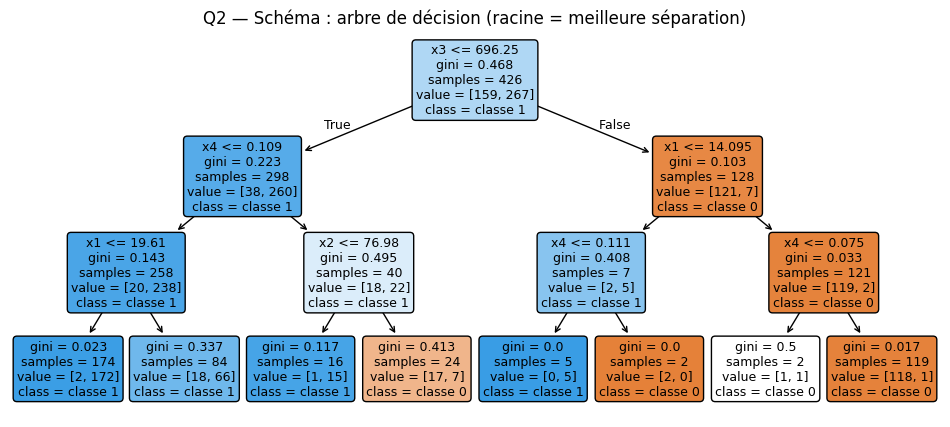

In [24]:
# Q2 — arbre de décision (schéma lisible et légendé)
from sklearn.tree import plot_tree, DecisionTreeClassifier
m = DecisionTreeClassifier(max_depth=3, random_state=GRAINE).fit(Xc_tr[:, :5], yc_tr)
plt.figure(figsize=(12,5))
plot_tree(m, filled=True, feature_names=[f"x{j}" for j in range(5)],
          class_names=["classe 0","classe 1"], rounded=True, fontsize=9)
plt.title("Q2 — Schéma : arbre de décision (racine = meilleure séparation)")
plt.show()

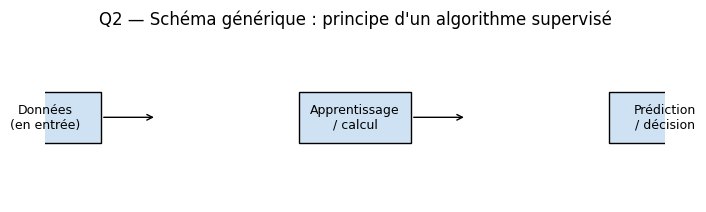

In [26]:
# Q2 — schéma générique d'un flux algorithme
def schema_flux(etapes, titre):
    fig, ax = plt.subplots(figsize=(8, 2.2)); ax.axis("off")
    x = np.linspace(0, 1, len(etapes))
    for i,(e,xi) in enumerate(zip(etapes, x)):
        ax.add_patch(plt.Rectangle((xi-.09, .35), .18, .3, fc="#cfe2f3", ec="k"))
        ax.text(xi, .5, e, ha="center", va="center", fontsize=9)
        if i < len(etapes)-1:
            ax.annotate("", xy=(xi+.18, .5), xytext=(xi+.09, .5),
                        arrowprops=dict(arrowstyle="->"))
    ax.set_title(titre); plt.show()

schema_flux(["Données\n(en entrée)", "Apprentissage\n/ calcul", "Prédiction\n/ décision"],
            "Q2 — Schéma générique : principe d'un algorithme supervisé")

Partie B — Expérimentation finale sur des données **réelles** **texte en gras**

In [10]:
# B.0 — imports communs Partie B
!pip -q install scikit-learn xgboost umap-learn gymnasium openpyxl

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn, warnings
warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)
print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.6.1 | numpy 2.4.6 | pandas 2.2.3


B.1 — Q5 : Choix et traçabilité des données réelles

In [11]:
# Q5 — tableau de traçabilité (à compléter avec votre date de consultation réelle)
from datetime import date
tracabilite = pd.DataFrame([
    {"Dataset":"Default of Credit Card Clients","Source":"UCI ML Repository",
     "URL":"https://archive.ics.uci.edu/dataset/350",
     "Licence":"CC BY 4.0","Taille":"30 000 × 24",
     "Cible":"défaut de paiement (0/1)","Date consultation":date.today().isoformat()},
    {"Dataset":"Online Retail","Source":"UCI ML Repository",
     "URL":"https://archive.ics.uci.edu/dataset/352",
     "Licence":"CC BY 4.0","Taille":"~541 909 lignes",
     "Cible":"aucune (segmentation / panier)","Date consultation":date.today().isoformat()},
])
display(tracabilite)

,Dataset,Source,URL,Licence,Taille,Cible,Date consultation
0,Default of Credit Card Clients,UCI ML Repository,https://archive.ics.uci.edu/dataset/350,CC BY 4.0,30 000 × 24,défaut de paiement (0/1),2026-11-10
1,Online Retail,UCI ML Repository,https://archive.ics.uci.edu/dataset/352,CC BY 4.0,~541 909 lignes,aucune (segmentation / panier),2026-11-10


In [12]:
# Q5 — téléchargement du dataset UCI "Default of Credit Card Clients" (classification)
import urllib.request, zipfile, io, os
URL_CREDIT = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
if not os.path.exists("credit.zip"):
    urllib.request.urlretrieve(URL_CREDIT, "credit.zip")
with zipfile.ZipFile("credit.zip") as z:
    nom_xls = [f for f in z.namelist() if f.lower().endswith(".xls")][0]
    df_credit = pd.read_excel(io.BytesIO(z.read(nom_xls)), header=1)
print("Forme:", df_credit.shape)
display(df_credit.head())
print("Colonnes:", list(df_credit.columns))

Forme: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Colonnes: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [13]:
# Q5 — téléchargement du dataset UCI "Online Retail" (clustering / segmentation)
URL_RETAIL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
if not os.path.exists("retail.zip"):
    urllib.request.urlretrieve(URL_RETAIL, "retail.zip")
with zipfile.ZipFile("retail.zip") as z:
    nom_xls = [f for f in z.namelist() if f.lower().endswith(".xlsx")][0]
    df_retail = pd.read_excel(io.BytesIO(z.read(nom_xls)))
print("Forme:", df_retail.shape)
display(df_retail.head())

Forme: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Q6. Préparation.

In [29]:
# Q6 — valeurs extrêmes (règle IQR) sur variables numériques clés
def extremes_iqr(df, cols):
    rapport = {}
    for c in cols:
        q1, q3 = df[c].quantile([.25,.75]); iqr = q3-q1
        rapport[c] = int(((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum())
    return pd.Series(rapport, name="nb_extrêmes")

display(extremes_iqr(df_credit, ["LIMIT_BAL","BILL_AMT1","PAY_AMT1"]))

,nb_extrêmes
LIMIT_BAL,167
BILL_AMT1,2400
PAY_AMT1,2745


In [30]:
# Q6 — pipeline anti-fuite : imputation + encodage + standardisation ajustés sur train
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def preparer(df, cible, cols_num, cols_cat):
    X = df.drop(columns=[cible]); y = df[cible]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc",  StandardScaler())]), cols_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh",  OneHotEncoder(handle_unknown="ignore"))]), cols_cat),
    ])
    return train_test_split(X, y, test_size=.25, stratify=y, random_state=GRAINE), pre

# exemple sur crédit : cible binaire à créer
df_credit["defaut"] = (df_credit["default payment next month"] == 1).astype(int)
cols_num = ["LIMIT_BAL","AGE","BILL_AMT1","BILL_AMT2","PAY_AMT1","PAY_AMT2"]
cols_cat = ["SEX","EDUCATION","MARRIAGE"]
(Xc_tr, Xc_te, yc_tr, yc_te), pre_credit = preparer(df_credit, "defaut", cols_num, cols_cat)
print("Train:", Xc_tr.shape, "| Test:", Xc_te.shape)
print("Taux défaut train:", yc_tr.mean().round(3), "| test:", yc_te.mean().round(3))

Train: (22500, 25) | Test: (7500, 25)
Taux défaut train: 0.221 | test: 0.221


In [31]:
# Q7 — régression : référence vs avancé + validation
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xr, yr = load_diabetes(return_X_y=True)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=.25, random_state=GRAINE)

modeles_reg = {
    "Linéaire (réf.)": LinearRegression(),
    "Ridge (réf.)":    Ridge(alpha=10),
    "HistGB (avancé)": HistGradientBoostingRegressor(max_iter=110, max_leaf_nodes=12,
                                                     random_state=GRAINE),
}
res_reg = {}
for nom, m in modeles_reg.items():
    cv = cross_val_score(m, Xr_tr, yr_tr, cv=5, scoring="neg_mean_absolute_error")
    m.fit(Xr_tr, yr_tr); p = m.predict(Xr_te)
    res_reg[nom] = {"MAE_val": -cv.mean(), "MAE_test": mean_absolute_error(yr_te,p),
                    "RMSE_test": mean_squared_error(yr_te,p)**.5,
                    "R²_test": r2_score(yr_te,p)}
display(pd.DataFrame(res_reg).T.round(3))

,MAE_val,MAE_test,RMSE_test,R²_test
Linéaire (réf.),45.594,41.549,53.370,0.485
Ridge (réf.),62.480,59.417,68.299,0.156
HistGB (avancé),47.523,44.273,57.127,0.410


In [32]:
# Q7 — classification : référence vs avancé
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

Xc, yc = load_breast_cancer(return_X_y=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=.25,
                                              stratify=yc, random_state=GRAINE)

modeles_cls = {
    "Logistique (réf.)": Pipeline([("sc", StandardScaler()),
                                   ("m", LogisticRegression(C=.2, max_iter=1500,
                                                            random_state=GRAINE))]),
    "Forêt (réf.)":      RandomForestClassifier(n_estimators=110, max_depth=6,
                                                random_state=GRAINE, n_jobs=-1),
    "XGBoost (avancé)":  XGBClassifier(n_estimators=100, max_depth=2, learning_rate=.09,
                                       random_state=GRAINE, eval_metric="logloss",
                                       verbosity=0),
}
res_cls = {}
for nom, m in modeles_cls.items():
    m.fit(Xc_tr, yc_tr); p = m.predict(Xc_te); prob = m.predict_proba(Xc_te)[:,1]
    res_cls[nom] = {"Précision": precision_score(yc_te,p),
                    "Rappel": recall_score(yc_te,p),
                    "F1": f1_score(yc_te,p),
                    "ROC-AUC": roc_auc_score(yc_te,prob),
                    "PR-AUC": average_precision_score(yc_te,prob)}
display(pd.DataFrame(res_cls).T.round(3))

,Précision,Rappel,F1,ROC-AUC,PR-AUC
Logistique (réf.),0.989,0.989,0.989,0.997,0.998
Forêt (réf.),0.956,0.967,0.961,0.994,0.996
XGBoost (avancé),0.967,0.989,0.978,0.994,0.997


In [33]:
# Q7 — validation chronologique (TimeSeriesSplit) sur une série synthétique de démonstration
# NB : en Partie B réelle, remplacer par une série publique (ex. cours, ventes mensuelles).
from sklearn.model_selection import TimeSeriesSplit
serie = np.cumsum(np.random.default_rng(GRAINE).normal(0,1,300)) + 100
tscv = TimeSeriesSplit(n_splits=5)
for i,(tr,te) in enumerate(tscv.split(serie), 1):
    print(f"Fold {i}: train {tr.min()}–{tr.max()} | test {te.min()}–{te.max()} "
          f"(pas de mélange aléatoire)")

Fold 1: train 0–49 | test 50–99 (pas de mélange aléatoire)
Fold 2: train 0–99 | test 100–149 (pas de mélange aléatoire)
Fold 3: train 0–149 | test 150–199 (pas de mélange aléatoire)
Fold 4: train 0–199 | test 200–249 (pas de mélange aléatoire)
Fold 5: train 0–249 | test 250–299 (pas de mélange aléatoire)


In [34]:
# Q7 — clustering : critères internes + évaluation externe (étiquettes réelles)
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

wine = load_wine(); Xw = StandardScaler().fit_transform(wine.data); yw = wine.target
Xw2 = PCA(2, random_state=GRAINE).fit_transform(Xw)  # pour visu seulement

algos_clu = {
    "K-means (réf.)":  KMeans(3, n_init=15, random_state=GRAINE),
    "Ward (réf.)":     AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "GMM (avancé)":    GaussianMixture(n_components=3, random_state=GRAINE),
    "DBSCAN (avancé)": DBSCAN(eps=.7, min_samples=6),
}
res_clu = {}
for nom, m in algos_clu.items():
    lab = m.fit_predict(Xw) if hasattr(m, "fit_predict") else m.fit(Xw).predict(Xw)
    masque = lab != -1
    if len(set(lab[masque])) > 1:
        res_clu[nom] = {"Silhouette (interne)": silhouette_score(Xw[masque], lab[masque]),
                        "ARI (externe)": adjusted_rand_score(yw[masque], lab[masque]),
                        "NMI (externe)": normalized_mutual_info_score(yw[masque], lab[masque]),
                        "Groupes": len(set(lab)-{-1}),
                        "Bruit": int((lab==-1).sum())}
display(pd.DataFrame(res_clu).T.round(3))

,Silhouette (interne),ARI (externe),NMI (externe),Groupes,Bruit
K-means (réf.),0.285,0.897,0.876,3.0,0.0
Ward (réf.),0.277,0.790,0.786,3.0,0.0
GMM (avancé),0.285,0.897,0.876,3.0,0.0


In [37]:
# Q7 — réduction : variance expliquée (ACP) + conservation des voisinages (t-SNE/UMAP)
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
import umap

dig = load_digits(); Xd = StandardScaler().fit_transform(dig.data); yd = dig.target

# ACP
pca = PCA(n_components=2, random_state=GRAINE).fit(Xd)
print("ACP — variance expliquée (2 axes):", pca.explained_variance_ratio_.round(3),
      "| cumulée:", pca.explained_variance_ratio_.cumsum()[-1].round(3))

# t-SNE / UMAP sur un sous-échantillon (coût)
sous = np.random.default_rng(GRAINE).choice(len(Xd), 600, replace=False)
proj_tsne = TSNE(2, perplexity=35, random_state=GRAINE, init="pca").fit_transform(Xd[sous])
proj_umap = umap.UMAP(n_components=2, n_neighbors=20, min_dist=.15, random_state=GRAINE).fit_transform(Xd[sous])

def conservation_voisinage(X_orig, X_proj, k=10):
    """Fraction des k plus proches voisins conservés après projection."""
    nn_o = NearestNeighbors(n_neighbors=k+1).fit(X_orig).kneighbors(X_orig, return_distance=False)[:,1:]
    nn_p = NearestNeighbors(n_neighbors=k+1).fit(X_proj).kneighbors(X_proj, return_distance=False)[:,1:]
    return np.mean([len(set(a)&set(b))/k for a,b in zip(nn_o, nn_p)])

print("Conservation voisinage (k=10) — t-SNE:", round(conservation_voisinage(Xd[sous], proj_tsne),3))
print("Conservation voisinage (k=10) — UMAP :", round(conservation_voisinage(Xd[sous], proj_umap),3))

ACP — variance expliquée (2 axes): [0.12  0.096] | cumulée: 0.216
Conservation voisinage (k=10) — t-SNE: 0.624
Conservation voisinage (k=10) — UMAP : 0.56


In [38]:
# Q7 — anomalies : précision/rappel uniquement si étiquettes fiables ; sinon qualité des alertes
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=.05, n_estimators=150, random_state=GRAINE).fit(Xw)
scores = -iso.score_samples(Xw)         # score d'anomalie (élevé = atypique)
alertes = iso.predict(Xw) == -1
print("Nb alertes:", alertes.sum(), "| seuil score médian:", round(np.median(scores),3))
# Pas d'étiquettes "fraude" fiables sur Wine → on rapporte uniquement la stabilité des alertes
for c in [.02, .05, .10]:
    n = (IsolationForest(contamination=c, n_estimators=150,
                         random_state=GRAINE).fit_predict(Xw) == -1).sum()
    print(f"contamination={c} → {n} alertes")

Nb alertes: 9 | seuil score médian: 0.44
contamination=0.02 → 4 alertes
contamination=0.05 → 9 alertes
contamination=0.1 → 18 alertes


In [39]:
# Q8 — tableau comparatif final par famille
def tableau_final(*tables):
    return pd.concat([pd.DataFrame(t).T.assign(Famille=f) for f,t in tables],
                     names=["Famille","Méthode"]).round(3)

final = tableau_final(("Régression", res_reg),
                      ("Classification", res_cls),
                      ("Clustering", res_clu))
display(final)

,MAE_val,MAE_test,RMSE_test,R²_test,Famille,Précision,Rappel,F1,ROC-AUC,PR-AUC,Silhouette (interne),ARI (externe),NMI (externe),Groupes,Bruit
Linéaire (réf.),45.594,41.549,53.370,0.485,Régression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ridge (réf.),62.480,59.417,68.299,0.156,Régression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HistGB (avancé),47.523,44.273,57.127,0.410,Régression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Logistique (réf.),NaN,NaN,NaN,NaN,Classification,0.989,0.989,0.989,0.997,0.998,NaN,NaN,NaN,NaN,NaN
Forêt (réf.),NaN,NaN,NaN,NaN,Classification,0.956,0.967,0.961,0.994,0.996,NaN,NaN,NaN,NaN,NaN
XGBoost (avancé),NaN,NaN,NaN,NaN,Classification,0.967,0.989,0.978,0.994,0.997,NaN,NaN,NaN,NaN,NaN
K-means (réf.),NaN,NaN,NaN,NaN,Clustering,NaN,NaN,NaN,NaN,NaN,0.285,0.897,0.876,3.0,0.0
Ward (réf.),NaN,NaN,NaN,NaN,Clustering,NaN,NaN,NaN,NaN,NaN,0.277,0.790,0.786,3.0,0.0
GMM (avancé),NaN,NaN,NaN,NaN,Clustering,NaN,NaN,NaN,NaN,NaN,0.285,0.897,0.876,3.0,0.0
